# S5 Soft Computing Experiment — Stability-Aware Re-Planning

Notebook ini menguji **S5 diagnostic feedback** secara agregat: *freeze served stops*, *re-sequence remaining stops*, quantile risk guidance, dan stability penalty.

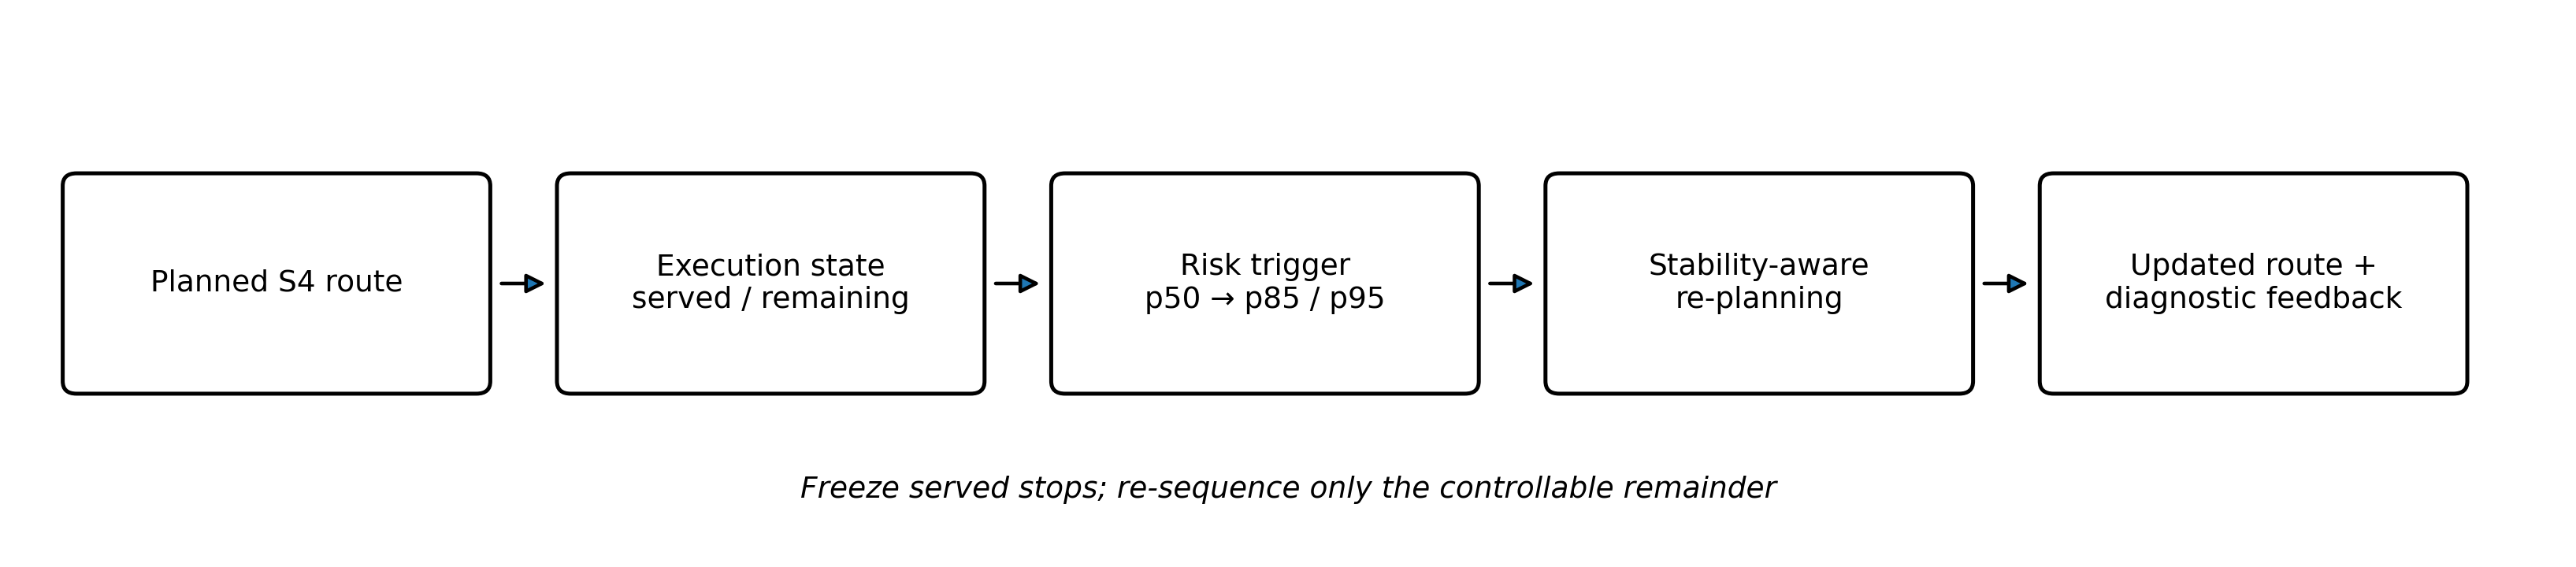

## Output utama
- Perbandingan **NR, FR, DP, RG, dan SA**.
- Skenario trigger 25%, 50%, dan 75%.
- Shock p50→p85 dan p50→p95.
- Local delay 10, 20, dan 30 menit.
- Re-planning gain, OTD, distance premium, SP, RSI, edge retention, changed stops, dan runtime.
- Uji Friedman, paired t-test atau Wilcoxon, Holm correction, dan effect size.
- Grafik, CSV, workbook hasil, kalimat hasil untuk paper, serta ZIP output.

> **Penting:** hasil final paper harus memakai file detail rute S4 yang sama dengan eksperimen disertasi. Jangan memakai tabel agregat S4 sebagai pengganti urutan rute per kendaraan.

## Paket input yang diperlukan

Unggah satu ZIP yang memuat:

```text
stops.csv
s4_routes.csv
combined_osrm_distance_matrix_km_long.csv
combined_travel_time_matrix_p50_long.csv
combined_travel_time_matrix_p85_long.csv
combined_travel_time_matrix_p95_long.csv
```

Kolom minimum:

- `stops.csv`: `delivery_date, node_id, weight_kg, volume_cm3, tw_start, tw_end, service_time_min`
- `s4_routes.csv`: `delivery_date, vehicle_id, sequence, node_id`
- file matriks: `delivery_date, origin_id, destination_id, <nilai numerik>`

Notebook melakukan deteksi nama kolom alternatif, audit coverage matriks, pemeriksaan node rute, dan pemeriksaan kapasitas sebelum eksperimen dimulai.

In [ ]:
from __future__ import annotations

import json
import math
import os
import random
import re
import shutil
import time
import warnings
import zipfile
from collections import defaultdict
from dataclasses import asdict, dataclass
from itertools import combinations
from pathlib import Path
from typing import Any, Callable, Iterable, Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)

# -----------------------------
# Configuration
# -----------------------------
CONFIG: dict[str, Any] = {
    "DATA_MODE": "auto",  # auto | upload_zip | drive_folder | demo
    "INPUT_DIR": "/content/s5_input",
    "OUTPUT_DIR": "/content/s5_output",
    "RESET_OUTPUT": False,
    "DRIVE_INPUT_DIR": "/content/drive/MyDrive/S5_Input",
    "RUN_MODE": "quick",  # quick | final
    "REQUIRE_EXISTING_S4": True,
    "ALLOW_REBUILD_S4": False,
    "FILE_OVERRIDES": {
        "stops": None,
        "routes": None,
        "distance": None,
        "p50": None,
        "p85": None,
        "p95": None,
    },
    "DEPOT_ID": None,
    "DEPOT_START_MIN": 8 * 60,
    "DEFAULT_SERVICE_MIN": 15.0,
    "VEHICLE_WEIGHT_CAPACITY_KG": 10_000.0,
    "VEHICLE_VOLUME_CAPACITY_CM3": 3_992_800.0,
    "MAX_STOPS_PER_ROUTE_FALLBACK": 25,
    "TRIGGER_FRACTIONS": [0.25, 0.50, 0.75],
    "SHOCK_QUANTILES": ["p85", "p95"],
    "LOCAL_DELAYS_MIN": [10.0, 20.0, 30.0],
    "LOCAL_DELAY_SCOPE": "all_active_routes",  # all_active_routes | one_random_vehicle
    "TRIGGER_LATENESS_THRESHOLD_MIN": 5.0,
    "THETA1_MIN": 5.0,
    "THETA2_MIN": 20.0,
    "MAIN_STABILITY_WEIGHT": 0.25,
    "STABILITY_WEIGHTS": [0.0, 0.10, 0.25, 0.50, 1.00],
    "RUN_STABILITY_SENSITIVITY": True,
    "SENSITIVITY_MAX_INSTANCES": 15,
    "SENSITIVITY_SEEDS": [0, 1, 2],
    "RISK_MULTIPLIERS": {"p50": 1.00, "p85": 1.1559, "p95": 1.2935},
    "METHOD_WEIGHTS": {
        "DP": {"distance": 0.80, "travel": 0.20, "lateness": 0.00, "risk": 0.00},
        "RG": {"distance": 0.15, "travel": 0.10, "lateness": 0.50, "risk": 0.25},
        "SA": {"distance": 0.15, "travel": 0.10, "lateness": 0.50, "risk": 0.25},
        "FR": {"distance": 0.10, "travel": 0.10, "lateness": 0.55, "risk": 0.25},
    },
    "DESTROY_RATE": 0.20,
    "SA_INITIAL_TEMPERATURE": 0.15,
    "SA_COOLING": 0.992,
    "NO_IMPROVEMENT_LIMIT": 45,
    "QUICK": {
        "MAX_INSTANCES": 5,
        "SEEDS": [0, 1],
        "ITERATIONS": 60,
        "TRIGGER_FRACTIONS": [0.25, 0.50],
        "SHOCK_QUANTILES": ["p85", "p95"],
        "LOCAL_DELAYS_MIN": [15.0, 30.0],
    },
    "FINAL": {
        "MAX_INSTANCES": None,
        "SEEDS": list(range(10)),
        "ITERATIONS": 160,
        "TRIGGER_FRACTIONS": [0.25, 0.50, 0.75],
        "SHOCK_QUANTILES": ["p85", "p95"],
        "LOCAL_DELAYS_MIN": [10.0, 20.0, 30.0],
    },
    "CHECKPOINT_EVERY_SCENARIO": True,
    "SAVE_ROUTE_LEVEL_DETAILS": True,
    "STRICT_MATRIX_COVERAGE": True,
    "EPS": 1e-9,
}


# -----------------------------
# Utility helpers
# -----------------------------
def in_colab() -> bool:
    try:
        import google.colab  # type: ignore
        return True
    except Exception:
        return False


def clean_name(x: Any) -> str:
    x = str(x).strip().lower()
    x = re.sub(r"[^a-z0-9]+", "_", x)
    return x.strip("_")


def norm_node(x: Any) -> str:
    if pd.isna(x):
        return ""
    if isinstance(x, float) and x.is_integer():
        return str(int(x))
    return str(x).strip()


def norm_date_series(s: pd.Series) -> pd.Series:
    dt = pd.to_datetime(s, errors="coerce")
    out = dt.dt.strftime("%Y-%m-%d")
    raw = s.astype(str).str.strip()
    return out.where(dt.notna(), raw)


def time_to_min(x: Any, default: float = 0.0) -> float:
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return float(default)
    if isinstance(x, (int, float, np.integer, np.floating)):
        v = float(x)
        # Excel fractions of a day
        if 0 <= v < 1:
            return v * 24 * 60
        return v
    if hasattr(x, "hour") and hasattr(x, "minute"):
        return float(x.hour * 60 + x.minute + getattr(x, "second", 0) / 60)
    text = str(x).strip()
    if not text:
        return float(default)
    try:
        td = pd.to_timedelta(text)
        return float(td.total_seconds() / 60)
    except Exception:
        pass
    try:
        dt = pd.to_datetime(text, errors="raise")
        return float(dt.hour * 60 + dt.minute + dt.second / 60)
    except Exception:
        return float(default)


def safe_div(a: float, b: float, eps: float = 1e-9) -> float:
    return float(a) / max(float(b), eps)


def ensure_dir(path: str | Path, clear: bool = False) -> Path:
    p = Path(path)
    if clear and p.exists():
        shutil.rmtree(p)
    p.mkdir(parents=True, exist_ok=True)
    return p


def read_table(path: Path) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix in {".csv", ".txt"}:
        try:
            return pd.read_csv(path)
        except UnicodeDecodeError:
            return pd.read_csv(path, encoding="latin1")
    if suffix in {".xlsx", ".xls"}:
        return pd.read_excel(path)
    if suffix == ".parquet":
        return pd.read_parquet(path)
    raise ValueError(f"Unsupported input format: {path}")


def write_json(path: Path, obj: Any) -> None:
    with path.open("w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)


ALIASES: dict[str, list[str]] = {
    "delivery_date": ["delivery_date", "date", "tanggal", "shipment_date", "deliverydate", "tgl_kirim"],
    "node_id": ["node_id", "customer_code", "customer_id", "node", "id", "kode_pelanggan", "destination_id"],
    "vehicle_id": ["vehicle_id", "route_id", "vehicle", "kendaraan", "truck_id", "armada_id", "route"],
    "sequence": ["sequence", "seq", "stop_sequence", "visit_order", "order", "urutan", "position", "pos"],
    "weight_kg": ["weight_kg", "weight", "berat_kg", "total_weight_kg", "demand_weight_kg", "berat"],
    "volume_cm3": ["volume_cm3", "volume", "total_volume_cm3", "demand_volume_cm3", "volume_cm_3"],
    "tw_start": ["tw_start", "time_window_start", "window_start", "start_time", "jam_mulai", "open_time", "a_i"],
    "tw_end": ["tw_end", "time_window_end", "window_end", "end_time", "jam_selesai", "close_time", "b_i"],
    "service_time_min": ["service_time_min", "service_min", "service_time", "waktu_pelayanan_min", "service_duration_min"],
    "origin_id": ["origin_id", "origin", "from_id", "source_id", "asal"],
    "destination_id": ["destination_id", "destination", "to_id", "target_id", "tujuan"],
    "node_type": ["node_type", "type", "jenis_node"],
    "latitude": ["latitude", "lat"],
    "longitude": ["longitude", "lon", "lng"],
}


def standardize_columns(df: pd.DataFrame, required: Iterable[str], optional: Iterable[str] = ()) -> pd.DataFrame:
    df = df.copy()
    original = {clean_name(c): c for c in df.columns}
    rename: dict[str, str] = {}
    for canonical in list(required) + list(optional):
        candidates = [clean_name(canonical)] + [clean_name(a) for a in ALIASES.get(canonical, [])]
        hit = next((original[c] for c in candidates if c in original), None)
        if hit is not None:
            rename[hit] = canonical
    df = df.rename(columns=rename)
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns {missing}. Available: {list(df.columns)}")
    return df


def score_file(path: Path, keywords: list[str], penalties: list[str] = []) -> int:
    n = clean_name(path.name)
    score = sum(5 for k in keywords if clean_name(k) in n)
    score -= sum(4 for k in penalties if clean_name(k) in n)
    return score


def discover_input_files(root: Path, overrides: dict[str, Optional[str]]) -> dict[str, Path]:
    files = [p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in {".csv", ".xlsx", ".xls", ".parquet"}]
    if not files:
        raise FileNotFoundError(f"No supported input files found under {root}")

    result: dict[str, Path] = {}
    for key, override in overrides.items():
        if override:
            p = Path(override)
            if not p.is_absolute():
                p = root / p
            if not p.exists():
                raise FileNotFoundError(f"Override for {key} does not exist: {p}")
            result[key] = p

    patterns = {
        "distance": (["distance", "matrix"], ["p50", "p85", "p95", "duration"]),
        "p50": (["p50", "matrix"], ["distance"]),
        "p85": (["p85", "matrix"], ["distance"]),
        "p95": (["p95", "matrix"], ["distance"]),
        "routes": (["s4", "route"], ["summary", "aggregate", "matrix"]),
        "stops": (["stop"], ["route", "matrix", "summary"]),
    }
    for key, (kw, pen) in patterns.items():
        if key in result:
            continue
        ranked = sorted(((score_file(p, kw, pen), p) for p in files), reverse=True, key=lambda x: x[0])
        if ranked and ranked[0][0] > 0:
            result[key] = ranked[0][1]

    # Column-based fallback for routes and stops
    if "routes" not in result or "stops" not in result:
        for p in files:
            if p in result.values():
                continue
            try:
                df = read_table(p).head(10)
                cols = {clean_name(c) for c in df.columns}
            except Exception:
                continue
            def has(alias_key: str) -> bool:
                return any(clean_name(a) in cols for a in [alias_key] + ALIASES.get(alias_key, []))
            if "routes" not in result and has("delivery_date") and has("vehicle_id") and has("sequence") and has("node_id"):
                result["routes"] = p
            if "stops" not in result and has("delivery_date") and has("node_id") and (has("tw_end") or has("weight_kg") or has("volume_cm3")):
                result["stops"] = p

    required_matrix = ["distance", "p50", "p85", "p95"]
    missing = [k for k in required_matrix if k not in result]
    if missing:
        raise FileNotFoundError(
            f"Could not automatically identify files for {missing}. Set CONFIG['FILE_OVERRIDES'] explicitly.\n"
            + "Files found:\n" + "\n".join(str(p) for p in files)
        )
    if "stops" not in result:
        raise FileNotFoundError("Could not identify the customer-day stop file.")
    return result


def prepare_matrix(path: Path, kind: str) -> pd.DataFrame:
    df = read_table(path)
    df = standardize_columns(df, ["origin_id", "destination_id"], ["delivery_date"])
    if "delivery_date" not in df.columns:
        df["delivery_date"] = "__GLOBAL__"
    df["delivery_date"] = norm_date_series(df["delivery_date"])
    df["origin_id"] = df["origin_id"].map(norm_node)
    df["destination_id"] = df["destination_id"].map(norm_node)
    key_cols = {"delivery_date", "origin_id", "destination_id"}
    numeric_candidates = []
    for c in df.columns:
        if c in key_cols:
            continue
        s = pd.to_numeric(df[c], errors="coerce")
        if s.notna().mean() > 0.7:
            numeric_candidates.append((s.notna().sum(), c))
    if not numeric_candidates:
        raise ValueError(f"No numeric matrix value column found in {path}")
    preferred = {
        "distance": ["distance_km", "distance", "value"],
        "p50": ["travel_time_min_p50", "travel_time_min", "duration_min", "value"],
        "p85": ["travel_time_min_p85", "travel_time_min", "duration_min", "value"],
        "p95": ["travel_time_min_p95", "travel_time_min", "duration_min", "value"],
    }
    value_col = None
    clean_map = {clean_name(c): c for c in df.columns}
    for name in preferred[kind]:
        if clean_name(name) in clean_map:
            value_col = clean_map[clean_name(name)]
            break
    if value_col is None:
        value_col = sorted(numeric_candidates, reverse=True)[0][1]
    out = df[["delivery_date", "origin_id", "destination_id", value_col]].copy()
    out = out.rename(columns={value_col: "value"})
    out["value"] = pd.to_numeric(out["value"], errors="coerce")
    out = out.dropna(subset=["value"])
    out["kind"] = kind
    return out


def prepare_stops(path: Path, default_service: float) -> pd.DataFrame:
    df = read_table(path)
    df = standardize_columns(
        df,
        ["delivery_date", "node_id"],
        ["weight_kg", "volume_cm3", "tw_start", "tw_end", "service_time_min", "node_type", "latitude", "longitude"],
    )
    df["delivery_date"] = norm_date_series(df["delivery_date"])
    df["node_id"] = df["node_id"].map(norm_node)
    for c in ["weight_kg", "volume_cm3"]:
        if c not in df.columns:
            df[c] = 0.0
        df[c] = pd.to_numeric(df[c], errors="coerce").fillna(0.0)
    if "tw_start" not in df.columns:
        df["tw_start"] = 0.0
    if "tw_end" not in df.columns:
        df["tw_end"] = 24 * 60.0
    df["tw_start_min"] = df["tw_start"].map(lambda x: time_to_min(x, 0.0))
    df["tw_end_min"] = df["tw_end"].map(lambda x: time_to_min(x, 24 * 60.0))
    if "service_time_min" not in df.columns:
        df["service_time_min"] = default_service
    df["service_time_min"] = pd.to_numeric(df["service_time_min"], errors="coerce").fillna(default_service)
    agg = {
        "weight_kg": "sum",
        "volume_cm3": "sum",
        "tw_start_min": "min",
        "tw_end_min": "min",
        "service_time_min": "max",
    }
    for c in ["node_type", "latitude", "longitude"]:
        if c in df.columns:
            agg[c] = "first"
    out = df.groupby(["delivery_date", "node_id"], as_index=False).agg(agg)
    return out


def prepare_routes(path: Path) -> pd.DataFrame:
    df = read_table(path)
    df = standardize_columns(df, ["delivery_date", "vehicle_id", "sequence", "node_id"])
    df["delivery_date"] = norm_date_series(df["delivery_date"])
    df["vehicle_id"] = df["vehicle_id"].map(norm_node)
    df["node_id"] = df["node_id"].map(norm_node)
    df["sequence"] = pd.to_numeric(df["sequence"], errors="coerce")
    df = df.dropna(subset=["sequence"])
    df["sequence"] = df["sequence"].astype(int)
    return df[["delivery_date", "vehicle_id", "sequence", "node_id"]].sort_values(
        ["delivery_date", "vehicle_id", "sequence"]
    )


@dataclass
class MatrixStore:
    data: dict[tuple[str, str], dict[tuple[str, str], float]]
    depot_id: str

    def get(self, date: str, kind: str, origin: str, destination: str) -> float:
        origin = norm_node(origin)
        destination = norm_node(destination)
        if origin == destination:
            return 0.0
        for key in [(date, kind), ("__GLOBAL__", kind)]:
            d = self.data.get(key)
            if d is not None and (origin, destination) in d:
                return float(d[(origin, destination)])
        raise KeyError(f"Missing {kind} matrix value for {date}: {origin} -> {destination}")


def build_matrix_store(frames: dict[str, pd.DataFrame], depot_id: str) -> MatrixStore:
    data: dict[tuple[str, str], dict[tuple[str, str], float]] = {}
    for kind, df in frames.items():
        for date, g in df.groupby("delivery_date"):
            data[(str(date), kind)] = {
                (norm_node(r.origin_id), norm_node(r.destination_id)): float(r.value)
                for r in g.itertuples(index=False)
            }
    return MatrixStore(data=data, depot_id=depot_id)


def infer_depot_id(stops: pd.DataFrame, matrices: dict[str, pd.DataFrame], override: Optional[str]) -> str:
    if override:
        return norm_node(override)
    if "node_type" in stops.columns:
        depot_rows = stops[stops["node_type"].astype(str).str.lower().str.contains("depot")]
        if not depot_rows.empty:
            return norm_node(depot_rows.iloc[0]["node_id"])
    stop_nodes = set(stops["node_id"].map(norm_node))
    all_nodes = pd.concat([matrices["distance"]["origin_id"], matrices["distance"]["destination_id"]]).map(norm_node)
    candidates = [x for x in all_nodes.value_counts().index if x not in stop_nodes]
    named = [x for x in all_nodes.unique() if "depot" in x.lower()]
    if named:
        return norm_node(named[0])
    if candidates:
        return norm_node(candidates[0])
    # If depot was included in stops, use a name-based fallback
    named_stops = [x for x in stops["node_id"].unique() if "depot" in str(x).lower()]
    if named_stops:
        return norm_node(named_stops[0])
    raise ValueError("Unable to infer depot ID. Set CONFIG['DEPOT_ID'] explicitly.")


def load_real_inputs(root: Path, cfg: dict[str, Any]) -> tuple[pd.DataFrame, pd.DataFrame, MatrixStore, dict[str, str]]:
    files = discover_input_files(root, cfg["FILE_OVERRIDES"])
    matrix_frames = {k: prepare_matrix(files[k], k) for k in ["distance", "p50", "p85", "p95"]}
    stops = prepare_stops(files["stops"], cfg["DEFAULT_SERVICE_MIN"])
    depot_id = infer_depot_id(stops, matrix_frames, cfg.get("DEPOT_ID"))
    # remove depot rows from customer stops
    stops = stops[stops["node_id"].map(norm_node) != depot_id].copy()
    store = build_matrix_store(matrix_frames, depot_id)
    if "routes" in files:
        routes = prepare_routes(files["routes"])
        routes = routes[routes["node_id"].map(norm_node) != depot_id].copy()
    else:
        if cfg["REQUIRE_EXISTING_S4"] and not cfg["ALLOW_REBUILD_S4"]:
            raise FileNotFoundError(
                "No S4 route-detail file was found. Real paper results require the exact S4 plan "
                "(delivery_date, vehicle_id, sequence, node_id). Set a routes override or enable fallback reconstruction."
            )
        routes = rebuild_s4_routes(stops, store, cfg)
    file_map = {k: str(v) for k, v in files.items()}
    return stops, routes, store, file_map


# -----------------------------
# Demo data
# -----------------------------
def generate_demo_data(cfg: dict[str, Any], n_instances: int = 4, seed: int = 42) -> tuple[pd.DataFrame, pd.DataFrame, MatrixStore, dict[str, str]]:
    rng = np.random.default_rng(seed)
    depot = "DEPOT_1"
    stop_rows: list[dict[str, Any]] = []
    route_rows: list[dict[str, Any]] = []
    matrix_rows: dict[str, list[dict[str, Any]]] = {k: [] for k in ["distance", "p50", "p85", "p95"]}
    multipliers = cfg["RISK_MULTIPLIERS"]
    for day in range(n_instances):
        date = (pd.Timestamp("2024-03-01") + pd.Timedelta(days=day)).strftime("%Y-%m-%d")
        n = int(rng.integers(16, 25))
        coords = {depot: np.array([0.0, 0.0])}
        nodes = []
        for i in range(n):
            node = f"C{day+1:02d}_{i+1:03d}"
            nodes.append(node)
            coords[node] = rng.normal(0, 10, size=2)
            tw_start = float(rng.integers(8 * 60, 12 * 60))
            width = float(rng.integers(120, 300))
            stop_rows.append({
                "delivery_date": date,
                "node_id": node,
                "weight_kg": float(rng.integers(50, 450)),
                "volume_cm3": float(rng.integers(80_000, 420_000)),
                "tw_start_min": tw_start,
                "tw_end_min": min(tw_start + width, 17 * 60),
                "service_time_min": float(rng.integers(8, 18)),
            })
        all_nodes = [depot] + nodes
        for o in all_nodes:
            for d in all_nodes:
                dist = float(np.linalg.norm(coords[o] - coords[d]) * 1.25)
                base = dist / 28.0 * 60.0 + (0 if o == d else 2.0)
                matrix_rows["distance"].append({"delivery_date": date, "origin_id": o, "destination_id": d, "value": dist, "kind": "distance"})
                for q in ["p50", "p85", "p95"]:
                    matrix_rows[q].append({"delivery_date": date, "origin_id": o, "destination_id": d, "value": base * multipliers[q], "kind": q})
        # two or three simple nearest-neighbour routes
        nveh = 2 if n < 21 else 3
        chunks = [nodes[i::nveh] for i in range(nveh)]
        for v, chunk in enumerate(chunks, start=1):
            cur = depot
            seq = []
            rem = set(chunk)
            while rem:
                nxt = min(rem, key=lambda x: np.linalg.norm(coords[cur] - coords[x]))
                seq.append(nxt)
                rem.remove(nxt)
                cur = nxt
            for pos, node in enumerate(seq, start=1):
                route_rows.append({"delivery_date": date, "vehicle_id": f"V{v}", "sequence": pos, "node_id": node})
    stops = pd.DataFrame(stop_rows)
    routes = pd.DataFrame(route_rows)
    frames = {k: pd.DataFrame(v) for k, v in matrix_rows.items()}
    store = build_matrix_store(frames, depot)
    return stops, routes, store, {"mode": "synthetic_demo"}


# -----------------------------
# Initial S4 fallback reconstruction
# -----------------------------
def rebuild_s4_routes(stops: pd.DataFrame, store: MatrixStore, cfg: dict[str, Any]) -> pd.DataFrame:
    rows: list[dict[str, Any]] = []
    for date, g in stops.groupby("delivery_date"):
        total_w = g["weight_kg"].sum()
        total_v = g["volume_cm3"].sum()
        nveh = max(
            1,
            math.ceil(total_w / cfg["VEHICLE_WEIGHT_CAPACITY_KG"]),
            math.ceil(total_v / cfg["VEHICLE_VOLUME_CAPACITY_CM3"]),
            math.ceil(len(g) / cfg["MAX_STOPS_PER_ROUTE_FALLBACK"]),
        )
        routes: list[list[str]] = [[] for _ in range(nveh)]
        load_w = [0.0] * nveh
        load_v = [0.0] * nveh
        # tight windows first
        for r in g.sort_values(["tw_end_min", "tw_start_min"]).itertuples(index=False):
            best = None
            for k in range(nveh):
                if load_w[k] + r.weight_kg > cfg["VEHICLE_WEIGHT_CAPACITY_KG"] + 1e-6:
                    continue
                if load_v[k] + r.volume_cm3 > cfg["VEHICLE_VOLUME_CAPACITY_CM3"] + 1e-6:
                    continue
                prev = routes[k][-1] if routes[k] else store.depot_id
                cost = store.get(str(date), "distance", prev, r.node_id)
                if best is None or cost < best[0]:
                    best = (cost, k)
            if best is None:
                routes.append([])
                load_w.append(0.0)
                load_v.append(0.0)
                best = (0.0, len(routes) - 1)
            k = best[1]
            routes[k].append(norm_node(r.node_id))
            load_w[k] += float(r.weight_kg)
            load_v[k] += float(r.volume_cm3)
        for k, seq in enumerate(routes, start=1):
            # nearest-neighbour reorder from depot as fallback only
            rem = set(seq)
            ordered: list[str] = []
            cur = store.depot_id
            while rem:
                nxt = min(rem, key=lambda x: store.get(str(date), "distance", cur, x))
                ordered.append(nxt)
                rem.remove(nxt)
                cur = nxt
            for pos, node in enumerate(ordered, start=1):
                rows.append({"delivery_date": str(date), "vehicle_id": f"V{k}", "sequence": pos, "node_id": node})
    return pd.DataFrame(rows)


# -----------------------------
# Validation
# -----------------------------
def validate_inputs(stops: pd.DataFrame, routes: pd.DataFrame, store: MatrixStore, cfg: dict[str, Any]) -> pd.DataFrame:
    report: list[dict[str, Any]] = []
    stop_key = set(zip(stops["delivery_date"].astype(str), stops["node_id"].map(norm_node)))
    route_key = set(zip(routes["delivery_date"].astype(str), routes["node_id"].map(norm_node)))
    missing_stops = route_key - stop_key
    report.append({"check": "route nodes present in stops", "status": "PASS" if not missing_stops else "FAIL", "detail": str(list(missing_stops)[:10])})
    duplicates = routes.duplicated(["delivery_date", "vehicle_id", "node_id"]).sum()
    report.append({"check": "duplicate customer in same route", "status": "PASS" if duplicates == 0 else "FAIL", "detail": int(duplicates)})
    missing_matrix = []
    for (date, veh), g in routes.groupby(["delivery_date", "vehicle_id"]):
        seq = [store.depot_id] + g.sort_values("sequence")["node_id"].map(norm_node).tolist() + [store.depot_id]
        for a, b in zip(seq[:-1], seq[1:]):
            for kind in ["distance", "p50", "p85", "p95"]:
                try:
                    store.get(str(date), kind, a, b)
                except KeyError:
                    missing_matrix.append((str(date), str(veh), a, b, kind))
    report.append({"check": "matrix coverage on S4 arcs", "status": "PASS" if not missing_matrix else "FAIL", "detail": str(missing_matrix[:10])})
    capacity_violations = []
    demand = stops.set_index(["delivery_date", "node_id"])[["weight_kg", "volume_cm3"]]
    for (date, veh), g in routes.groupby(["delivery_date", "vehicle_id"]):
        keys = [(str(date), norm_node(n)) for n in g["node_id"]]
        w = sum(float(demand.loc[k, "weight_kg"]) for k in keys if k in demand.index)
        v = sum(float(demand.loc[k, "volume_cm3"]) for k in keys if k in demand.index)
        if w > cfg["VEHICLE_WEIGHT_CAPACITY_KG"] + 1e-6 or v > cfg["VEHICLE_VOLUME_CAPACITY_CM3"] + 1e-6:
            capacity_violations.append((date, veh, w, v))
    report.append({"check": "S4 route capacity", "status": "PASS" if not capacity_violations else "WARN", "detail": str(capacity_violations[:10])})
    rep = pd.DataFrame(report)
    if cfg["STRICT_MATRIX_COVERAGE"] and any((rep["check"] == "matrix coverage on S4 arcs") & (rep["status"] == "FAIL")):
        raise ValueError("Matrix coverage validation failed. See validation report.")
    if any((rep["check"] == "route nodes present in stops") & (rep["status"] == "FAIL")):
        raise ValueError("S4 routes contain nodes that are not present in the stop table.")
    return rep


# -----------------------------
# Routing simulation and metrics
# -----------------------------
@dataclass
class StopInfo:
    node_id: str
    weight_kg: float
    volume_cm3: float
    tw_start: float
    tw_end: float
    service: float


@dataclass
class RouteContext:
    date: str
    vehicle_id: str
    original_full: list[str]
    served: list[str]
    remaining: list[str]
    current_node: str
    current_time: float
    prefix_distance: float
    prefix_travel_time: float
    prefix_lateness: float
    prefix_ontime: int
    prefix_count: int
    local_delay: float
    old_positions: dict[str, int]


def build_stop_lookup(stops: pd.DataFrame) -> dict[tuple[str, str], StopInfo]:
    result: dict[tuple[str, str], StopInfo] = {}
    for r in stops.itertuples(index=False):
        result[(str(r.delivery_date), norm_node(r.node_id))] = StopInfo(
            node_id=norm_node(r.node_id),
            weight_kg=float(r.weight_kg),
            volume_cm3=float(r.volume_cm3),
            tw_start=float(r.tw_start_min),
            tw_end=float(r.tw_end_min),
            service=float(r.service_time_min),
        )
    return result


def route_metrics(
    date: str,
    sequence: list[str] | tuple[str, ...],
    current_node: str,
    current_time: float,
    q: str,
    store: MatrixStore,
    stop_lookup: dict[tuple[str, str], StopInfo],
    include_detail: bool = False,
) -> dict[str, Any]:
    prev = norm_node(current_node)
    t = float(current_time)
    total_dist = 0.0
    total_tt = 0.0
    total_wait = 0.0
    total_late = 0.0
    ontime = 0
    detail: list[dict[str, Any]] = []
    for pos, node in enumerate(sequence, start=1):
        node = norm_node(node)
        dist = store.get(date, "distance", prev, node)
        tt = store.get(date, q, prev, node)
        total_dist += dist
        total_tt += tt
        arrival = t + tt
        info = stop_lookup[(date, node)]
        service_start = max(arrival, info.tw_start)
        wait = max(0.0, info.tw_start - arrival)
        late = max(0.0, service_start - info.tw_end)
        depart = service_start + info.service
        total_wait += wait
        total_late += late
        ontime += int(late <= 1e-9)
        if include_detail:
            detail.append({
                "position": pos,
                "node_id": node,
                "from_node": prev,
                "distance_km": dist,
                "travel_time_min": tt,
                "arrival_min": arrival,
                "service_start_min": service_start,
                "departure_min": depart,
                "waiting_min": wait,
                "lateness_min": late,
                "on_time": int(late <= 1e-9),
                "quantile": q,
            })
        t = depart
        prev = node
    if sequence:
        total_dist += store.get(date, "distance", prev, store.depot_id)
        total_tt += store.get(date, q, prev, store.depot_id)
        t += store.get(date, q, prev, store.depot_id)
    return {
        "distance": float(total_dist),
        "travel_time": float(total_tt),
        "waiting": float(total_wait),
        "lateness": float(total_late),
        "ontime_count": int(ontime),
        "customer_count": int(len(sequence)),
        "otd": 100.0 * safe_div(ontime, len(sequence), 1.0) if len(sequence) else 100.0,
        "end_time": float(t),
        "detail": detail,
    }


def stability_metrics(old_sequence: list[str], new_sequence: list[str]) -> dict[str, float]:
    if not old_sequence:
        return {"sp": 0.0, "rsi": 1.0, "changed_stops": 0.0, "edge_retention": 1.0}
    old_pos = {n: i for i, n in enumerate(old_sequence)}
    new_pos = {n: i for i, n in enumerate(new_sequence)}
    common = [n for n in old_sequence if n in new_pos]
    denom = max(1, len(common) * max(1, len(common) - 1))
    sp = sum(abs(new_pos[n] - old_pos[n]) for n in common) / denom
    changed = sum(int(new_pos[n] != old_pos[n]) for n in common)
    old_edges = set(zip(old_sequence[:-1], old_sequence[1:]))
    new_edges = set(zip(new_sequence[:-1], new_sequence[1:]))
    edge_ret = safe_div(len(old_edges & new_edges), len(old_edges), 1.0) if old_edges else 1.0
    return {
        "sp": float(min(max(sp, 0.0), 1.0)),
        "rsi": float(1.0 - min(max(sp, 0.0), 1.0)),
        "changed_stops": float(changed),
        "edge_retention": float(edge_ret),
    }


def simulate_prefix(
    date: str,
    full_sequence: list[str],
    served_count: int,
    store: MatrixStore,
    stop_lookup: dict[tuple[str, str], StopInfo],
    depot_start: float,
) -> dict[str, Any]:
    served = full_sequence[:served_count]
    m = route_metrics(date, served, store.depot_id, depot_start, "p50", store, stop_lookup, include_detail=True)
    current_node = served[-1] if served else store.depot_id
    if served:
        current_time = m["detail"][-1]["departure_min"]
    else:
        current_time = depot_start
    return {"served": served, "current_node": current_node, "current_time": current_time, "metrics": m}


def create_contexts(
    date: str,
    date_routes: pd.DataFrame,
    trigger_fraction: float,
    local_delay: float,
    delay_scope: str,
    seed: int,
    store: MatrixStore,
    stop_lookup: dict[tuple[str, str], StopInfo],
    cfg: dict[str, Any],
) -> list[RouteContext]:
    rng = random.Random(seed + int(trigger_fraction * 1000) + int(local_delay * 10))
    grouped = []
    for veh, g in date_routes.groupby("vehicle_id"):
        seq = g.sort_values("sequence")["node_id"].map(norm_node).tolist()
        grouped.append((norm_node(veh), seq))
    active_vehicle_for_delay = None
    if delay_scope == "one_random_vehicle" and grouped:
        active_vehicle_for_delay = rng.choice([v for v, seq in grouped if seq])
    contexts = []
    for veh, seq in grouped:
        n = len(seq)
        if n <= 1:
            served_count = 0
        else:
            served_count = min(max(int(math.floor(n * trigger_fraction)), 0), n - 1)
        prefix = simulate_prefix(date, seq, served_count, store, stop_lookup, cfg["DEPOT_START_MIN"])
        delay = local_delay if delay_scope == "all_active_routes" or veh == active_vehicle_for_delay else 0.0
        remaining = seq[served_count:]
        contexts.append(RouteContext(
            date=date,
            vehicle_id=veh,
            original_full=seq,
            served=prefix["served"],
            remaining=remaining,
            current_node=prefix["current_node"],
            current_time=float(prefix["current_time"] + delay),
            prefix_distance=float(prefix["metrics"]["distance"]),
            prefix_travel_time=float(prefix["metrics"]["travel_time"]),
            prefix_lateness=float(prefix["metrics"]["lateness"]),
            prefix_ontime=int(prefix["metrics"]["ontime_count"]),
            prefix_count=int(prefix["metrics"]["customer_count"]),
            local_delay=float(delay),
            old_positions={n: i for i, n in enumerate(remaining)},
        ))
    return contexts


def choose_search_quantile(ctx: RouteContext, shock_q: str, store: MatrixStore, stop_lookup: dict[tuple[str, str], StopInfo], cfg: dict[str, Any]) -> str:
    p50 = route_metrics(ctx.date, ctx.remaining, ctx.current_node, ctx.current_time, "p50", store, stop_lookup)
    lp = float(p50["lateness"])
    if lp <= cfg["THETA1_MIN"]:
        selected = "p50"
    elif lp <= cfg["THETA2_MIN"]:
        selected = "p85"
    else:
        selected = "p95"
    order = {"p50": 0, "p85": 1, "p95": 2}
    return selected if order[selected] >= order[shock_q] else shock_q


# -----------------------------
# ALNS route optimizer
# -----------------------------
class RouteEvaluator:
    def __init__(
        self,
        ctx: RouteContext,
        search_q: str,
        method: str,
        stability_weight: float,
        store: MatrixStore,
        stop_lookup: dict[tuple[str, str], StopInfo],
        cfg: dict[str, Any],
    ) -> None:
        self.ctx = ctx
        self.search_q = search_q
        self.method = method
        self.stability_weight = float(stability_weight)
        self.store = store
        self.stop_lookup = stop_lookup
        self.cfg = cfg
        self.cache: dict[tuple[str, ...], tuple[float, dict[str, Any]]] = {}
        base = route_metrics(ctx.date, ctx.remaining, ctx.current_node, ctx.current_time, search_q, store, stop_lookup)
        self.scale_d = max(base["distance"], 1.0)
        self.scale_t = max(base["travel_time"], 1.0)
        self.scale_l = max(base["lateness"], max(1.0, len(ctx.remaining)))

    def evaluate(self, sequence: list[str] | tuple[str, ...]) -> tuple[float, dict[str, Any]]:
        key = tuple(sequence)
        if key in self.cache:
            return self.cache[key]
        m = route_metrics(self.ctx.date, list(key), self.ctx.current_node, self.ctx.current_time, self.search_q, self.store, self.stop_lookup)
        stab = stability_metrics(self.ctx.remaining, list(key))
        w = self.cfg["METHOD_WEIGHTS"][self.method]
        risk_factor = self.cfg["RISK_MULTIPLIERS"][self.search_q]
        obj = (
            w["distance"] * m["distance"] / self.scale_d
            + w["travel"] * m["travel_time"] / self.scale_t
            + w["lateness"] * m["lateness"] / self.scale_l
            + w["risk"] * risk_factor * m["lateness"] / self.scale_l
            + self.stability_weight * stab["sp"]
        )
        payload = {**m, **stab, "objective": float(obj)}
        self.cache[key] = (float(obj), payload)
        return self.cache[key]


def relatedness(node_a: str, node_b: str, date: str, store: MatrixStore, stop_lookup: dict[tuple[str, str], StopInfo]) -> float:
    d = store.get(date, "distance", node_a, node_b)
    a = stop_lookup[(date, node_a)]
    b = stop_lookup[(date, node_b)]
    tw = abs(a.tw_start - b.tw_start) / 60.0 + abs(a.tw_end - b.tw_end) / 60.0
    return d + 0.25 * tw


def destroy_sequence(seq: list[str], evaluator: RouteEvaluator, rng: random.Random, rate: float) -> tuple[list[str], list[str]]:
    if len(seq) <= 2:
        return [], seq.copy()
    r = max(1, min(len(seq) - 1, int(round(len(seq) * rate))))
    op = rng.choice(["random", "worst", "related"])
    if op == "random":
        removed = rng.sample(seq, r)
    elif op == "worst":
        detail = route_metrics(
            evaluator.ctx.date, seq, evaluator.ctx.current_node, evaluator.ctx.current_time,
            evaluator.search_q, evaluator.store, evaluator.stop_lookup, include_detail=True
        )["detail"]
        scores = {row["node_id"]: row["lateness_min"] + 0.01 * row["travel_time_min"] for row in detail}
        removed = sorted(seq, key=lambda n: scores.get(n, 0.0), reverse=True)[:r]
    else:
        seed_node = rng.choice(seq)
        removed = sorted(
            seq,
            key=lambda n: relatedness(seed_node, n, evaluator.ctx.date, evaluator.store, evaluator.stop_lookup),
        )[:r]
    removed_set = set(removed)
    partial = [n for n in seq if n not in removed_set]
    return partial, removed


def greedy_repair(partial: list[str], removed: list[str], evaluator: RouteEvaluator, rng: random.Random, regret: bool = False) -> list[str]:
    seq = partial.copy()
    pool = removed.copy()
    rng.shuffle(pool)
    while pool:
        best_global = None
        for node in pool:
            candidates = []
            for pos in range(len(seq) + 1):
                cand = seq[:pos] + [node] + seq[pos:]
                obj, _ = evaluator.evaluate(cand)
                candidates.append((obj, pos))
            candidates.sort()
            if regret and len(candidates) >= 2:
                priority = candidates[1][0] - candidates[0][0]
                key = (-priority, candidates[0][0])
            else:
                key = (candidates[0][0],)
            item = (key, node, candidates[0][1])
            if best_global is None or item[0] < best_global[0]:
                best_global = item
        assert best_global is not None
        _, node, pos = best_global
        seq.insert(pos, node)
        pool.remove(node)
    return seq


def local_search(seq: list[str], evaluator: RouteEvaluator, rng: random.Random, attempts: int = 12) -> list[str]:
    best = seq.copy()
    best_obj, _ = evaluator.evaluate(best)
    n = len(best)
    if n < 2:
        return best
    for _ in range(attempts):
        cand = best.copy()
        op = rng.choice(["swap", "relocate", "2opt"])
        if op == "swap":
            i, j = rng.sample(range(n), 2)
            cand[i], cand[j] = cand[j], cand[i]
        elif op == "relocate":
            i, j = rng.sample(range(n), 2)
            node = cand.pop(i)
            cand.insert(j, node)
        else:
            i, j = sorted(rng.sample(range(n), 2))
            cand[i:j+1] = reversed(cand[i:j+1])
        obj, _ = evaluator.evaluate(cand)
        if obj < best_obj - 1e-12:
            best, best_obj = cand, obj
    return best


def optimize_route(
    ctx: RouteContext,
    method: str,
    shock_q: str,
    stability_weight: float,
    seed: int,
    iterations: int,
    store: MatrixStore,
    stop_lookup: dict[tuple[str, str], StopInfo],
    cfg: dict[str, Any],
) -> tuple[list[str], dict[str, Any]]:
    start = time.perf_counter()
    if len(ctx.remaining) <= 1:
        return ctx.remaining.copy(), {"runtime": time.perf_counter() - start, "iterations": 0, "search_q": shock_q}
    search_q = shock_q if method == "DP" else choose_search_quantile(ctx, shock_q, store, stop_lookup, cfg)
    evaluator = RouteEvaluator(ctx, search_q, method, stability_weight, store, stop_lookup, cfg)
    rng = random.Random(seed)
    current = ctx.remaining.copy()
    current_obj, _ = evaluator.evaluate(current)
    best = current.copy()
    best_obj = current_obj
    temp = float(cfg["SA_INITIAL_TEMPERATURE"])
    no_imp = 0
    performed = 0
    for it in range(iterations):
        performed += 1
        partial, removed = destroy_sequence(current, evaluator, rng, cfg["DESTROY_RATE"])
        candidate = greedy_repair(partial, removed, evaluator, rng, regret=(it % 2 == 0))
        if it % 5 == 0:
            candidate = local_search(candidate, evaluator, rng, attempts=10)
        cand_obj, _ = evaluator.evaluate(candidate)
        delta = cand_obj - current_obj
        if delta <= 0 or rng.random() < math.exp(-delta / max(temp, 1e-9)):
            current, current_obj = candidate, cand_obj
        if cand_obj < best_obj - 1e-12:
            best, best_obj = candidate.copy(), cand_obj
            no_imp = 0
        else:
            no_imp += 1
        temp *= cfg["SA_COOLING"]
        if no_imp >= cfg["NO_IMPROVEMENT_LIMIT"]:
            break
    return best, {
        "runtime": float(time.perf_counter() - start),
        "iterations": performed,
        "search_q": search_q,
        "best_objective": best_obj,
        "cache_size": len(evaluator.cache),
    }


# -----------------------------
# Global remaining-stop reoptimization (FR benchmark)
# -----------------------------
class GlobalEvaluator:
    def __init__(
        self,
        contexts: list[RouteContext],
        search_qs: dict[str, str],
        store: MatrixStore,
        stop_lookup: dict[tuple[str, str], StopInfo],
        cfg: dict[str, Any],
    ) -> None:
        self.contexts = {c.vehicle_id: c for c in contexts}
        self.search_qs = search_qs
        self.store = store
        self.stop_lookup = stop_lookup
        self.cfg = cfg
        self.base_solution = {c.vehicle_id: c.remaining.copy() for c in contexts}
        self.base_metrics = self.aggregate(self.base_solution)
        self.scale_d = max(self.base_metrics["distance"], 1.0)
        self.scale_t = max(self.base_metrics["travel_time"], 1.0)
        self.scale_l = max(self.base_metrics["lateness"], sum(len(c.remaining) for c in contexts), 1.0)
        self.cache: dict[tuple[tuple[str, tuple[str, ...]], ...], tuple[float, dict[str, Any]]] = {}

    def route_capacity_ok(self, date: str, seq: list[str]) -> bool:
        w = sum(self.stop_lookup[(date, n)].weight_kg for n in seq)
        v = sum(self.stop_lookup[(date, n)].volume_cm3 for n in seq)
        return w <= self.cfg["VEHICLE_WEIGHT_CAPACITY_KG"] + 1e-6 and v <= self.cfg["VEHICLE_VOLUME_CAPACITY_CM3"] + 1e-6

    def aggregate(self, solution: dict[str, list[str]]) -> dict[str, Any]:
        total = defaultdict(float)
        feasible = True
        for veh, seq in solution.items():
            ctx = self.contexts[veh]
            if not self.route_capacity_ok(ctx.date, seq):
                feasible = False
            q = self.search_qs[veh]
            m = route_metrics(ctx.date, seq, ctx.current_node, ctx.current_time, q, self.store, self.stop_lookup)
            total["distance"] += m["distance"]
            total["travel_time"] += m["travel_time"]
            total["lateness"] += m["lateness"]
            total["customer_count"] += m["customer_count"]
            total["ontime_count"] += m["ontime_count"]
        total["otd"] = 100 * safe_div(total["ontime_count"], total["customer_count"], 1.0)
        total["feasible"] = feasible
        return dict(total)

    def evaluate(self, solution: dict[str, list[str]]) -> tuple[float, dict[str, Any]]:
        key = tuple(sorted((v, tuple(seq)) for v, seq in solution.items()))
        if key in self.cache:
            return self.cache[key]
        m = self.aggregate(solution)
        if not m["feasible"]:
            obj = 1e6
        else:
            w = self.cfg["METHOD_WEIGHTS"]["FR"]
            avg_risk = np.mean([self.cfg["RISK_MULTIPLIERS"][q] for q in self.search_qs.values()])
            obj = (
                w["distance"] * m["distance"] / self.scale_d
                + w["travel"] * m["travel_time"] / self.scale_t
                + w["lateness"] * m["lateness"] / self.scale_l
                + w["risk"] * avg_risk * m["lateness"] / self.scale_l
            )
        payload = {**m, "objective": float(obj)}
        self.cache[key] = (float(obj), payload)
        return self.cache[key]


def copy_solution(solution: dict[str, list[str]]) -> dict[str, list[str]]:
    return {k: v.copy() for k, v in solution.items()}


def optimize_global_fr(
    contexts: list[RouteContext],
    shock_q: str,
    seed: int,
    iterations: int,
    store: MatrixStore,
    stop_lookup: dict[tuple[str, str], StopInfo],
    cfg: dict[str, Any],
) -> tuple[dict[str, list[str]], dict[str, Any]]:
    start = time.perf_counter()
    active = [c for c in contexts if c.remaining]
    if not active:
        return {c.vehicle_id: [] for c in contexts}, {"runtime": 0.0, "iterations": 0}
    search_qs = {c.vehicle_id: choose_search_quantile(c, shock_q, store, stop_lookup, cfg) for c in active}
    evaluator = GlobalEvaluator(active, search_qs, store, stop_lookup, cfg)
    rng = random.Random(seed + 991)
    current = {c.vehicle_id: c.remaining.copy() for c in active}
    current_obj, _ = evaluator.evaluate(current)
    best = copy_solution(current)
    best_obj = current_obj
    temp = cfg["SA_INITIAL_TEMPERATURE"]
    no_imp = 0
    performed = 0
    for it in range(max(20, int(iterations * 0.7))):
        performed += 1
        cand = copy_solution(current)
        all_customers = [(v, n) for v, seq in cand.items() for n in seq]
        if len(all_customers) <= 2:
            break
        r = max(1, min(len(all_customers)-1, int(round(len(all_customers) * cfg["DESTROY_RATE"]))))
        removed_pairs = rng.sample(all_customers, r)
        removed_nodes = [n for _, n in removed_pairs]
        for v, n in removed_pairs:
            cand[v].remove(n)
        rng.shuffle(removed_nodes)
        feasible_repair = True
        for node in removed_nodes:
            best_ins = None
            for veh, seq in cand.items():
                ctx = evaluator.contexts[veh]
                for pos in range(len(seq)+1):
                    new_seq = seq[:pos] + [node] + seq[pos:]
                    if not evaluator.route_capacity_ok(ctx.date, new_seq):
                        continue
                    trial = copy_solution(cand)
                    trial[veh] = new_seq
                    obj, _ = evaluator.evaluate(trial)
                    if best_ins is None or obj < best_ins[0]:
                        best_ins = (obj, veh, pos)
            if best_ins is None:
                feasible_repair = False
                break
            _, veh, pos = best_ins
            cand[veh].insert(pos, node)
        if not feasible_repair:
            continue
        cand_obj, _ = evaluator.evaluate(cand)
        delta = cand_obj - current_obj
        if delta <= 0 or rng.random() < math.exp(-delta / max(temp, 1e-9)):
            current, current_obj = cand, cand_obj
        if cand_obj < best_obj - 1e-12:
            best, best_obj = copy_solution(cand), cand_obj
            no_imp = 0
        else:
            no_imp += 1
        temp *= cfg["SA_COOLING"]
        if no_imp >= cfg["NO_IMPROVEMENT_LIMIT"]:
            break
    # retain empty routes from original context list
    full = {c.vehicle_id: best.get(c.vehicle_id, []) for c in contexts}
    return full, {
        "runtime": float(time.perf_counter() - start),
        "iterations": performed,
        "best_objective": best_obj,
        "search_qs": search_qs,
        "cache_size": len(evaluator.cache),
        "optimistic_cross_vehicle_reassignment": True,
    }


# -----------------------------
# Experiment evaluation
# -----------------------------
def aggregate_method_result(
    method: str,
    contexts: list[RouteContext],
    solution: dict[str, list[str]],
    shock_q: str,
    runtime: float,
    optimization_meta: dict[str, Any],
    store: MatrixStore,
    stop_lookup: dict[tuple[str, str], StopInfo],
    include_route_detail: bool,
) -> tuple[dict[str, Any], list[dict[str, Any]]]:
    agg = defaultdict(float)
    route_rows: list[dict[str, Any]] = []
    for ctx in contexts:
        seq = solution.get(ctx.vehicle_id, ctx.remaining)
        m = route_metrics(ctx.date, seq, ctx.current_node, ctx.current_time, shock_q, store, stop_lookup, include_detail=include_route_detail)
        stab = stability_metrics(ctx.remaining, seq)
        agg["remaining_distance_km"] += m["distance"]
        agg["remaining_travel_time_min"] += m["travel_time"]
        agg["remaining_waiting_min"] += m["waiting"]
        agg["remaining_lateness_min"] += m["lateness"]
        agg["remaining_ontime_count"] += m["ontime_count"]
        agg["remaining_customer_count"] += m["customer_count"]
        agg["prefix_distance_km"] += ctx.prefix_distance
        agg["prefix_travel_time_min"] += ctx.prefix_travel_time
        agg["prefix_lateness_min"] += ctx.prefix_lateness
        agg["prefix_ontime_count"] += ctx.prefix_ontime
        agg["prefix_customer_count"] += ctx.prefix_count
        agg["sp_weighted"] += stab["sp"] * max(1, len(ctx.remaining))
        agg["rsi_weighted"] += stab["rsi"] * max(1, len(ctx.remaining))
        agg["edge_retention_weighted"] += stab["edge_retention"] * max(1, len(ctx.remaining))
        agg["stability_weight_total"] += max(1, len(ctx.remaining))
        agg["changed_stops"] += stab["changed_stops"]
        route_rows.append({
            "delivery_date": ctx.date,
            "vehicle_id": ctx.vehicle_id,
            "method": method,
            "old_remaining_sequence": " > ".join(ctx.remaining),
            "new_remaining_sequence": " > ".join(seq),
            "remaining_customers": len(seq),
            "remaining_distance_km": m["distance"],
            "remaining_travel_time_min": m["travel_time"],
            "remaining_lateness_min": m["lateness"],
            "remaining_otd_pct": m["otd"],
            **stab,
        })
    remaining_n = int(agg["remaining_customer_count"])
    total_n = int(agg["remaining_customer_count"] + agg["prefix_customer_count"])
    result = {
        "method": method,
        "remaining_distance_km": float(agg["remaining_distance_km"]),
        "remaining_travel_time_min": float(agg["remaining_travel_time_min"]),
        "remaining_waiting_min": float(agg["remaining_waiting_min"]),
        "remaining_lateness_min": float(agg["remaining_lateness_min"]),
        "remaining_otd_pct": 100.0 * safe_div(agg["remaining_ontime_count"], remaining_n, 1.0) if remaining_n else 100.0,
        "total_distance_km": float(agg["remaining_distance_km"] + agg["prefix_distance_km"]),
        "total_travel_time_min": float(agg["remaining_travel_time_min"] + agg["prefix_travel_time_min"]),
        "total_lateness_min": float(agg["remaining_lateness_min"] + agg["prefix_lateness_min"]),
        "total_otd_pct": 100.0 * safe_div(agg["remaining_ontime_count"] + agg["prefix_ontime_count"], total_n, 1.0) if total_n else 100.0,
        "remaining_customer_count": remaining_n,
        "total_customer_count": total_n,
        "sp": safe_div(agg["sp_weighted"], agg["stability_weight_total"], 1.0),
        "rsi": safe_div(agg["rsi_weighted"], agg["stability_weight_total"], 1.0),
        "edge_retention": safe_div(agg["edge_retention_weighted"], agg["stability_weight_total"], 1.0),
        "changed_stops": int(agg["changed_stops"]),
        "runtime_sec": float(runtime),
        "optimization_meta": json.dumps(optimization_meta, default=str),
    }
    return result, route_rows


def run_one_scenario(
    date: str,
    date_routes: pd.DataFrame,
    trigger_fraction: float,
    shock_q: str,
    local_delay: float,
    seed: int,
    iterations: int,
    store: MatrixStore,
    stop_lookup: dict[tuple[str, str], StopInfo],
    cfg: dict[str, Any],
    stability_weight: Optional[float] = None,
    methods: tuple[str, ...] = ("NR", "FR", "DP", "RG", "SA"),
) -> tuple[list[dict[str, Any]], list[dict[str, Any]]]:
    contexts = create_contexts(
        date, date_routes, trigger_fraction, local_delay, cfg["LOCAL_DELAY_SCOPE"], seed,
        store, stop_lookup, cfg
    )
    nr_solution = {c.vehicle_id: c.remaining.copy() for c in contexts}
    nr_eval, _ = aggregate_method_result("NR", contexts, nr_solution, shock_q, 0.0, {}, store, stop_lookup, False)
    triggered = nr_eval["remaining_lateness_min"] > cfg["TRIGGER_LATENESS_THRESHOLD_MIN"]
    triggered_routes = 0
    for c in contexts:
        m = route_metrics(c.date, c.remaining, c.current_node, c.current_time, shock_q, store, stop_lookup)
        triggered_routes += int(m["lateness"] > cfg["TRIGGER_LATENESS_THRESHOLD_MIN"])
    results: list[dict[str, Any]] = []
    route_details: list[dict[str, Any]] = []
    main_stability = cfg["MAIN_STABILITY_WEIGHT"] if stability_weight is None else float(stability_weight)

    for method in methods:
        method_start = time.perf_counter()
        meta: dict[str, Any] = {"triggered": triggered, "triggered_routes": triggered_routes}
        if method == "NR" or not triggered:
            solution = nr_solution
            runtime = 0.0
            meta["action"] = "retain_original_remaining_sequence"
        elif method == "FR":
            solution, fr_meta = optimize_global_fr(contexts, shock_q, seed, iterations, store, stop_lookup, cfg)
            runtime = fr_meta["runtime"]
            meta.update(fr_meta)
        else:
            solution = {}
            total_opt_runtime = 0.0
            route_meta = {}
            for i, ctx in enumerate(contexts):
                base_m = route_metrics(ctx.date, ctx.remaining, ctx.current_node, ctx.current_time, shock_q, store, stop_lookup)
                route_triggered = base_m["lateness"] > cfg["TRIGGER_LATENESS_THRESHOLD_MIN"]
                if not route_triggered:
                    solution[ctx.vehicle_id] = ctx.remaining.copy()
                    route_meta[ctx.vehicle_id] = {"action": "not_triggered"}
                    continue
                sw = main_stability if method == "SA" else 0.0
                seq, rmeta = optimize_route(
                    ctx, method, shock_q, sw, seed + i * 10007, iterations,
                    store, stop_lookup, cfg
                )
                solution[ctx.vehicle_id] = seq
                total_opt_runtime += rmeta["runtime"]
                route_meta[ctx.vehicle_id] = rmeta
            runtime = total_opt_runtime
            meta["route_meta"] = route_meta
            meta["stability_weight"] = main_stability if method == "SA" else 0.0
        result, rdetail = aggregate_method_result(
            method, contexts, solution, shock_q, runtime, meta,
            store, stop_lookup, cfg["SAVE_ROUTE_LEVEL_DETAILS"]
        )
        result.update({
            "delivery_date": date,
            "trigger_fraction": trigger_fraction,
            "shock_quantile": shock_q,
            "local_delay_min": local_delay,
            "seed": seed,
            "triggered": bool(triggered),
            "triggered_routes": int(triggered_routes),
            "stability_weight": main_stability if method == "SA" else 0.0,
            "scenario_runtime_wall_sec": float(time.perf_counter() - method_start),
        })
        for row in rdetail:
            row.update({
                "trigger_fraction": trigger_fraction,
                "shock_quantile": shock_q,
                "local_delay_min": local_delay,
                "seed": seed,
                "stability_weight": main_stability if method == "SA" else 0.0,
            })
        results.append(result)
        route_details.extend(rdetail)
    return results, route_details


def add_instance_size(routes: pd.DataFrame) -> dict[str, str]:
    counts = routes.groupby("delivery_date")["node_id"].nunique().sort_values()
    if len(counts) < 3:
        return {str(d): "all" for d in counts.index}
    ranks = counts.rank(method="first", pct=True)
    return {str(d): ("small" if r <= 1/3 else "medium" if r <= 2/3 else "large") for d, r in ranks.items()}


def effective_run_config(cfg: dict[str, Any]) -> dict[str, Any]:
    mode = cfg["RUN_MODE"].upper()
    profile = cfg[mode]
    return {
        "max_instances": profile["MAX_INSTANCES"],
        "seeds": profile["SEEDS"],
        "iterations": profile["ITERATIONS"],
        "trigger_fractions": profile["TRIGGER_FRACTIONS"],
        "shock_quantiles": profile["SHOCK_QUANTILES"],
        "local_delays": profile["LOCAL_DELAYS_MIN"],
    }


def run_experiment(
    stops: pd.DataFrame,
    routes: pd.DataFrame,
    store: MatrixStore,
    output_dir: Path,
    cfg: dict[str, Any],
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    stop_lookup = build_stop_lookup(stops)
    eff = effective_run_config(cfg)
    dates = sorted(set(routes["delivery_date"].astype(str)))
    if eff["max_instances"]:
        dates = dates[: int(eff["max_instances"])]
    size_map = add_instance_size(routes)
    checkpoint = output_dir / "s5_results_raw_checkpoint.csv"
    route_checkpoint = output_dir / "s5_route_details_checkpoint.csv"
    failure_path = output_dir / "s5_failures.csv"
    if checkpoint.exists():
        raw_existing = pd.read_csv(checkpoint)
    else:
        raw_existing = pd.DataFrame()
    if route_checkpoint.exists():
        route_existing = pd.read_csv(route_checkpoint)
    else:
        route_existing = pd.DataFrame()
    failures: list[dict[str, Any]] = []
    all_rows = raw_existing.to_dict("records") if not raw_existing.empty else []
    all_route_rows = route_existing.to_dict("records") if not route_existing.empty else []
    completed = set()
    if not raw_existing.empty:
        key_cols = ["delivery_date", "trigger_fraction", "shock_quantile", "local_delay_min", "seed"]
        for key, g in raw_existing.groupby(key_cols):
            if set(g["method"]) >= {"NR", "FR", "DP", "RG", "SA"}:
                completed.add(tuple(key))
    total_scenarios = len(dates) * len(eff["trigger_fractions"]) * len(eff["shock_quantiles"]) * len(eff["local_delays"]) * len(eff["seeds"])
    counter = 0
    print(f"Running {total_scenarios} scenario blocks across {len(dates)} instances. Resume blocks found: {len(completed)}")
    for date in dates:
        date_routes = routes[routes["delivery_date"].astype(str) == date].copy()
        for trigger in eff["trigger_fractions"]:
            for shock in eff["shock_quantiles"]:
                for delay in eff["local_delays"]:
                    for seed in eff["seeds"]:
                        counter += 1
                        key = (date, float(trigger), str(shock), float(delay), int(seed))
                        if key in completed:
                            continue
                        print(f"[{counter}/{total_scenarios}] {date} trigger={trigger:.2f}, shock={shock}, delay={delay}, seed={seed}")
                        try:
                            rows, rrows = run_one_scenario(
                                date, date_routes, float(trigger), str(shock), float(delay), int(seed),
                                int(eff["iterations"]), store, stop_lookup, cfg
                            )
                            for row in rows:
                                row["instance_size"] = size_map.get(date, "unknown")
                            all_rows.extend(rows)
                            all_route_rows.extend(rrows)
                        except Exception as exc:
                            failures.append({
                                "delivery_date": date,
                                "trigger_fraction": trigger,
                                "shock_quantile": shock,
                                "local_delay_min": delay,
                                "seed": seed,
                                "error_type": type(exc).__name__,
                                "error": str(exc),
                            })
                            print("  FAILED:", type(exc).__name__, exc)
                        if cfg["CHECKPOINT_EVERY_SCENARIO"]:
                            pd.DataFrame(all_rows).to_csv(checkpoint, index=False)
                            if cfg["SAVE_ROUTE_LEVEL_DETAILS"]:
                                pd.DataFrame(all_route_rows).to_csv(route_checkpoint, index=False)
                            if failures:
                                pd.DataFrame(failures).to_csv(failure_path, index=False)
    raw = pd.DataFrame(all_rows)
    route_detail = pd.DataFrame(all_route_rows)
    failures_df = pd.DataFrame(failures)
    raw.to_csv(output_dir / "s5_results_raw.csv", index=False)
    if cfg["SAVE_ROUTE_LEVEL_DETAILS"]:
        route_detail.to_csv(output_dir / "s5_route_details.csv", index=False)
    failures_df.to_csv(output_dir / "s5_failures.csv", index=False)
    return raw, route_detail, failures_df


# -----------------------------
# Optional stability sensitivity
# -----------------------------
def run_stability_sensitivity(
    routes: pd.DataFrame,
    store: MatrixStore,
    stop_lookup: dict[tuple[str, str], StopInfo],
    output_dir: Path,
    cfg: dict[str, Any],
) -> pd.DataFrame:
    if not cfg["RUN_STABILITY_SENSITIVITY"]:
        return pd.DataFrame()
    dates = sorted(routes["delivery_date"].astype(str).unique())[: cfg["SENSITIVITY_MAX_INSTANCES"]]
    trigger = 0.50
    shock = "p95"
    delay = 20.0
    rows = []
    eff = effective_run_config(cfg)
    iterations = max(40, int(eff["iterations"] * 0.75))
    for date in dates:
        date_routes = routes[routes["delivery_date"].astype(str) == date]
        for seed in cfg["SENSITIVITY_SEEDS"]:
            for weight in cfg["STABILITY_WEIGHTS"]:
                out, _ = run_one_scenario(
                    date, date_routes, trigger, shock, delay, int(seed), iterations,
                    store, stop_lookup, cfg, stability_weight=float(weight), methods=("NR", "SA")
                )
                for r in out:
                    if r["method"] == "SA":
                        r["stability_weight"] = float(weight)
                        rows.append(r)
    df = pd.DataFrame(rows)
    df.to_csv(output_dir / "s5_stability_sensitivity_raw.csv", index=False)
    return df


# -----------------------------
# Aggregation, statistics, and figures
# -----------------------------
def attach_nr_comparisons(raw: pd.DataFrame) -> pd.DataFrame:
    if raw.empty:
        return raw
    key_cols = ["delivery_date", "trigger_fraction", "shock_quantile", "local_delay_min", "seed"]
    nr = raw[raw["method"] == "NR"][key_cols + ["remaining_lateness_min", "remaining_otd_pct", "remaining_distance_km"]].rename(
        columns={
            "remaining_lateness_min": "nr_lateness_min",
            "remaining_otd_pct": "nr_otd_pct",
            "remaining_distance_km": "nr_distance_km",
        }
    )
    out = raw.merge(nr, on=key_cols, how="left")
    out["replanning_gain_lateness_pct"] = 100 * (out["nr_lateness_min"] - out["remaining_lateness_min"]) / out["nr_lateness_min"].clip(lower=1e-9)
    out["otd_gain_pp"] = out["remaining_otd_pct"] - out["nr_otd_pct"]
    out["distance_premium_pct"] = 100 * (out["remaining_distance_km"] - out["nr_distance_km"]) / out["nr_distance_km"].clip(lower=1e-9)
    out.loc[out["nr_lateness_min"] <= 1e-9, "replanning_gain_lateness_pct"] = 0.0
    return out


def aggregate_tables(raw: pd.DataFrame, sensitivity: pd.DataFrame, output_dir: Path) -> dict[str, pd.DataFrame]:
    raw2 = attach_nr_comparisons(raw)
    method_summary = raw2.groupby("method", as_index=False).agg(
        lateness_mean=("remaining_lateness_min", "mean"),
        lateness_median=("remaining_lateness_min", "median"),
        otd_mean=("remaining_otd_pct", "mean"),
        distance_mean=("remaining_distance_km", "mean"),
        rsi_mean=("rsi", "mean"),
        edge_retention_mean=("edge_retention", "mean"),
        changed_stops_mean=("changed_stops", "mean"),
        runtime_median=("runtime_sec", "median"),
        replanning_gain_mean=("replanning_gain_lateness_pct", "mean"),
        otd_gain_mean=("otd_gain_pp", "mean"),
        distance_premium_mean=("distance_premium_pct", "mean"),
        triggered_rate=("triggered", "mean"),
        n=("delivery_date", "size"),
    )
    by_trigger = raw2.groupby(["method", "trigger_fraction"], as_index=False).agg(
        lateness_mean=("remaining_lateness_min", "mean"),
        otd_mean=("remaining_otd_pct", "mean"),
        rsi_mean=("rsi", "mean"),
        replanning_gain_mean=("replanning_gain_lateness_pct", "mean"),
        runtime_median=("runtime_sec", "median"),
    )
    by_severity = raw2.groupby(["method", "shock_quantile", "local_delay_min"], as_index=False).agg(
        lateness_mean=("remaining_lateness_min", "mean"),
        otd_mean=("remaining_otd_pct", "mean"),
        rsi_mean=("rsi", "mean"),
        replanning_gain_mean=("replanning_gain_lateness_pct", "mean"),
    )
    by_size = raw2.groupby(["method", "instance_size"], as_index=False).agg(
        lateness_mean=("remaining_lateness_min", "mean"),
        otd_mean=("remaining_otd_pct", "mean"),
        rsi_mean=("rsi", "mean"),
        runtime_median=("runtime_sec", "median"),
    )
    sens_summary = pd.DataFrame()
    if not sensitivity.empty:
        sens2 = attach_nr_comparisons(sensitivity)
        sens_summary = sens2.groupby("stability_weight", as_index=False).agg(
            lateness_mean=("remaining_lateness_min", "mean"),
            otd_mean=("remaining_otd_pct", "mean"),
            sp_mean=("sp", "mean"),
            rsi_mean=("rsi", "mean"),
            distance_premium_mean=("distance_premium_pct", "mean"),
            replanning_gain_mean=("replanning_gain_lateness_pct", "mean"),
            runtime_median=("runtime_sec", "median"),
        )
    tables = {
        "raw_with_comparisons": raw2,
        "aggregate_by_method": method_summary,
        "by_trigger": by_trigger,
        "by_severity": by_severity,
        "by_instance_size": by_size,
        "stability_sensitivity": sens_summary,
    }
    for name, df in tables.items():
        df.to_csv(output_dir / f"{name}.csv", index=False)
    return tables


def holm_adjust(pvals: list[float]) -> list[float]:
    m = len(pvals)
    order = np.argsort(pvals)
    adjusted = np.empty(m, dtype=float)
    running = 0.0
    for rank, idx in enumerate(order):
        val = (m - rank) * pvals[idx]
        running = max(running, val)
        adjusted[idx] = min(1.0, running)
    return adjusted.tolist()


def rank_biserial(diffs: np.ndarray) -> float:
    diffs = np.asarray(diffs, dtype=float)
    diffs = diffs[np.isfinite(diffs) & (np.abs(diffs) > 1e-12)]
    if len(diffs) == 0:
        return 0.0
    ranks = stats.rankdata(np.abs(diffs))
    wplus = ranks[diffs > 0].sum()
    wminus = ranks[diffs < 0].sum()
    return float((wplus - wminus) / max(wplus + wminus, 1e-9))


def statistical_tests(raw: pd.DataFrame, output_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    if raw.empty:
        return pd.DataFrame(), pd.DataFrame()
    # Average metaheuristic seeds first to avoid treating seeds as independent operational observations.
    block_cols = ["delivery_date", "trigger_fraction", "shock_quantile", "local_delay_min"]
    agg = raw.groupby(block_cols + ["method"], as_index=False).agg(
        lateness=("remaining_lateness_min", "mean"),
        otd=("remaining_otd_pct", "mean"),
        rsi=("rsi", "mean"),
    )
    methods = [m for m in ["NR", "FR", "DP", "RG", "SA"] if m in set(agg["method"])]
    pair_rows = []
    for metric in ["lateness", "otd", "rsi"]:
        pivot = agg.pivot_table(index=block_cols, columns="method", values=metric, aggfunc="mean").dropna(subset=methods)
        metric_rows = []
        for a, b in combinations(methods, 2):
            x = pivot[a].to_numpy(float)
            y = pivot[b].to_numpy(float)
            diffs = x - y
            normal_p = stats.shapiro(diffs).pvalue if 3 <= len(diffs) <= 5000 else np.nan
            if len(diffs) < 2 or np.all(np.abs(diffs) < 1e-12):
                test_name, statv, pval, effect_name, effect = "no_variation", 0.0, 1.0, "none", 0.0
            elif np.isfinite(normal_p) and normal_p > 0.05:
                test = stats.ttest_rel(x, y, nan_policy="omit")
                sd = np.std(diffs, ddof=1)
                effect = float(np.mean(diffs) / sd) if sd > 1e-12 else 0.0
                test_name, statv, pval, effect_name = "paired_t", float(test.statistic), float(test.pvalue), "paired_cohens_d"
            else:
                test = stats.wilcoxon(x, y, zero_method="wilcox", alternative="two-sided", mode="auto")
                effect = rank_biserial(diffs)
                test_name, statv, pval, effect_name = "wilcoxon", float(test.statistic), float(test.pvalue), "rank_biserial"
            metric_rows.append({
                "metric": metric,
                "method_a": a,
                "method_b": b,
                "n_blocks": len(diffs),
                "mean_a_minus_b": float(np.mean(diffs)) if len(diffs) else np.nan,
                "normality_p": normal_p,
                "test": test_name,
                "statistic": statv,
                "p_value": pval,
                "effect_name": effect_name,
                "effect_size": effect,
            })
        adj = holm_adjust([r["p_value"] for r in metric_rows]) if metric_rows else []
        for r, p in zip(metric_rows, adj):
            r["p_holm"] = p
        pair_rows.extend(metric_rows)
    pair_df = pd.DataFrame(pair_rows)
    friedman_rows = []
    for metric in ["lateness", "otd", "rsi"]:
        pivot = agg.pivot_table(index=block_cols, columns="method", values=metric, aggfunc="mean").dropna(subset=methods)
        if len(pivot) >= 2 and len(methods) >= 3:
            test = stats.friedmanchisquare(*[pivot[m].to_numpy(float) for m in methods])
            friedman_rows.append({"metric": metric, "methods": ",".join(methods), "n_blocks": len(pivot), "statistic": float(test.statistic), "p_value": float(test.pvalue)})
    friedman_df = pd.DataFrame(friedman_rows)
    pair_df.to_csv(output_dir / "paired_statistical_tests.csv", index=False)
    friedman_df.to_csv(output_dir / "friedman_tests.csv", index=False)
    return pair_df, friedman_df


def make_figures(tables: dict[str, pd.DataFrame], output_dir: Path) -> list[Path]:
    raw = tables["raw_with_comparisons"]
    figs: list[Path] = []
    if raw.empty:
        return figs
    order = [m for m in ["NR", "FR", "DP", "RG", "SA"] if m in raw["method"].unique()]

    fig, ax = plt.subplots(figsize=(8, 5))
    data = [raw.loc[raw["method"] == m, "remaining_lateness_min"].to_numpy() for m in order]
    ax.boxplot(data, labels=order, showfliers=False)
    ax.set_ylabel("Remaining-route lateness (min)")
    ax.set_xlabel("Method")
    ax.set_title("S5 lateness under disruption")
    ax.grid(axis="y", alpha=0.25)
    p = output_dir / "fig_lateness_by_method.png"
    fig.tight_layout(); fig.savefig(p, dpi=300); plt.close(fig); figs.append(p)

    fig, ax = plt.subplots(figsize=(8, 5))
    data = [raw.loc[raw["method"] == m, "remaining_otd_pct"].to_numpy() for m in order]
    ax.boxplot(data, labels=order, showfliers=False)
    ax.set_ylabel("Remaining-customer OTD (%)")
    ax.set_xlabel("Method")
    ax.set_title("S5 on-time delivery under disruption")
    ax.grid(axis="y", alpha=0.25)
    p = output_dir / "fig_otd_by_method.png"
    fig.tight_layout(); fig.savefig(p, dpi=300); plt.close(fig); figs.append(p)

    summary = tables["aggregate_by_method"]
    fig, ax = plt.subplots(figsize=(7, 5))
    for r in summary.itertuples(index=False):
        ax.scatter(r.rsi_mean, r.replanning_gain_mean, s=65)
        ax.annotate(r.method, (r.rsi_mean, r.replanning_gain_mean), xytext=(5, 4), textcoords="offset points")
    ax.set_xlabel("Route Stability Index (RSI)")
    ax.set_ylabel("Mean lateness re-planning gain (%)")
    ax.set_title("Reliability–stability trade-off")
    ax.grid(alpha=0.25)
    p = output_dir / "fig_reliability_stability_tradeoff.png"
    fig.tight_layout(); fig.savefig(p, dpi=300); plt.close(fig); figs.append(p)

    trg = tables["by_trigger"]
    fig, ax = plt.subplots(figsize=(8, 5))
    for m in order:
        g = trg[trg["method"] == m].sort_values("trigger_fraction")
        if not g.empty:
            ax.plot(g["trigger_fraction"] * 100, g["lateness_mean"], marker="o", label=m)
    ax.set_xlabel("Completed visits at trigger (%)")
    ax.set_ylabel("Mean remaining lateness (min)")
    ax.set_title("Effect of re-planning timing")
    ax.legend()
    ax.grid(alpha=0.25)
    p = output_dir / "fig_trigger_effect.png"
    fig.tight_layout(); fig.savefig(p, dpi=300); plt.close(fig); figs.append(p)

    size = tables["by_instance_size"]
    if not size.empty:
        fig, ax = plt.subplots(figsize=(8, 5))
        labels = ["small", "medium", "large"]
        x = np.arange(len(labels))
        width = 0.8 / max(1, len(order))
        for i, m in enumerate(order):
            g = size[size["method"] == m].set_index("instance_size")
            vals = [g.loc[l, "runtime_median"] if l in g.index else np.nan for l in labels]
            ax.bar(x + (i - (len(order)-1)/2) * width, vals, width=width, label=m)
        ax.set_xticks(x); ax.set_xticklabels(labels)
        ax.set_ylabel("Median runtime (s)")
        ax.set_xlabel("Instance size")
        ax.set_title("Runtime by instance size")
        ax.legend()
        ax.grid(axis="y", alpha=0.25)
        p = output_dir / "fig_runtime_by_size.png"
        fig.tight_layout(); fig.savefig(p, dpi=300); plt.close(fig); figs.append(p)

    sens = tables["stability_sensitivity"]
    if not sens.empty:
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.plot(sens["stability_weight"], sens["replanning_gain_mean"], marker="o", label="Lateness gain")
        ax.set_xlabel("Stability weight")
        ax.set_ylabel("Mean lateness re-planning gain (%)")
        ax2 = ax.twinx()
        ax2.plot(sens["stability_weight"], sens["rsi_mean"], marker="s", label="RSI")
        ax2.set_ylabel("Mean RSI")
        ax.set_title("Sensitivity to stability weight")
        ax.grid(alpha=0.25)
        p = output_dir / "fig_stability_weight_sensitivity.png"
        fig.tight_layout(); fig.savefig(p, dpi=300); plt.close(fig); figs.append(p)
    return figs


def result_sentence_pack(
    tables: dict[str, pd.DataFrame], pair_tests: pd.DataFrame, output_dir: Path
) -> str:
    summary = tables["aggregate_by_method"].set_index("method")
    def val(method: str, col: str, default=np.nan):
        return float(summary.loc[method, col]) if method in summary.index else default
    sa_gain = val("SA", "replanning_gain_mean")
    sa_otd = val("SA", "otd_gain_mean")
    sa_rsi = val("SA", "rsi_mean")
    sa_runtime = val("SA", "runtime_median")
    rg_late = val("RG", "lateness_mean")
    sa_late = val("SA", "lateness_mean")
    dp_late = val("DP", "lateness_mean")
    nr_late = val("NR", "lateness_mean")
    test_line = "No paired test was available."
    if not pair_tests.empty:
        hit = pair_tests[(pair_tests["metric"] == "lateness") & (
            ((pair_tests["method_a"] == "NR") & (pair_tests["method_b"] == "SA")) |
            ((pair_tests["method_a"] == "SA") & (pair_tests["method_b"] == "NR"))
        )]
        if not hit.empty:
            r = hit.iloc[0]
            test_line = f"NR–SA paired comparison: {r['test']}, Holm-adjusted p={r['p_holm']:.4g}, {r['effect_name']}={r['effect_size']:.3f}."
    otd_verb = "improved" if sa_otd >= 0 else "changed"
    text = f"""SOFT COMPUTING S5 — AUTO-GENERATED RESULT SENTENCES

Primary aggregate statement
Across the evaluated daily instances and prespecified disruption settings, SA reduced remaining-route lateness by {sa_gain:.2f}% relative to no re-planning and {otd_verb} remaining-customer OTD by {sa_otd:.2f} percentage points. Its mean route-stability index was {sa_rsi:.3f}, with a median runtime of {sa_runtime:.3f} seconds per scenario block. {test_line}

Comparison statement
Mean remaining-route lateness was {nr_late:.2f} min for NR, {dp_late:.2f} min for DP, {rg_late:.2f} min for RG, and {sa_late:.2f} min for SA. Interpret SA versus RG jointly with RSI: a smaller lateness gain may be acceptable only when the stability improvement is operationally meaningful and statistically supported.

Submission warning
These sentences are valid only for the exact input package and configuration recorded in results_manifest.json. Do not combine them with the older S0–S4 aggregate values as evidence of S5 performance.
"""
    (output_dir / "paper_result_sentences.txt").write_text(text, encoding="utf-8")
    return text


def export_excel_like_bundle(
    tables: dict[str, pd.DataFrame], pair_tests: pd.DataFrame, friedman: pd.DataFrame, failures: pd.DataFrame, output_dir: Path
) -> Optional[Path]:
    # Excel output is convenient in Colab. CSV files remain the source-of-truth outputs.
    path = output_dir / "Soft_Computing_S5_Results.xlsx"
    try:
        with pd.ExcelWriter(path, engine="openpyxl") as writer:
            for name, df in tables.items():
                df.to_excel(writer, sheet_name=name[:31], index=False)
            pair_tests.to_excel(writer, sheet_name="paired_tests", index=False)
            friedman.to_excel(writer, sheet_name="friedman", index=False)
            failures.to_excel(writer, sheet_name="failures", index=False)
        return path
    except Exception as exc:
        print("Excel bundle skipped:", exc)
        return None


def finalize_outputs(
    raw: pd.DataFrame,
    sensitivity: pd.DataFrame,
    failures: pd.DataFrame,
    output_dir: Path,
    cfg: dict[str, Any],
    file_map: dict[str, str],
) -> dict[str, Any]:
    tables = aggregate_tables(raw, sensitivity, output_dir)
    pair_tests, friedman = statistical_tests(raw, output_dir)
    figs = make_figures(tables, output_dir)
    sentences = result_sentence_pack(tables, pair_tests, output_dir)
    excel_path = export_excel_like_bundle(tables, pair_tests, friedman, failures, output_dir)
    manifest = {
        "created_at_utc": pd.Timestamp.utcnow().isoformat(),
        "configuration": cfg,
        "input_files": file_map,
        "n_raw_rows": int(len(raw)),
        "n_failures": int(len(failures)),
        "figures": [str(p.name) for p in figs],
        "excel_bundle": str(excel_path.name) if excel_path else None,
        "method_definitions": {
            "NR": "No re-planning",
            "FR": "Optimistic unrestricted remaining-stop reoptimization; allows cross-vehicle reassignment and therefore is not directly implementable without load transfer",
            "DP": "Freeze served stops; distance-based per-route re-sequencing",
            "RG": "Freeze served stops; quantile risk-guided per-route re-sequencing without stability penalty",
            "SA": "Proposed stability-aware quantile risk-guided per-route re-sequencing",
        },
    }
    write_json(output_dir / "results_manifest.json", manifest)
    zip_path = output_dir.parent / "Soft_Computing_S5_Results.zip"
    if zip_path.exists():
        zip_path.unlink()
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for p in output_dir.rglob("*"):
            if p.is_file():
                zf.write(p, arcname=p.relative_to(output_dir.parent))
    return {"tables": tables, "pair_tests": pair_tests, "friedman": friedman, "figures": figs, "sentences": sentences, "zip_path": zip_path, "manifest": manifest}


# -----------------------------
# Input acquisition for Colab
# -----------------------------
def acquire_input(cfg: dict[str, Any]) -> tuple[pd.DataFrame, pd.DataFrame, MatrixStore, dict[str, str], Path]:
    mode = cfg["DATA_MODE"]
    if mode == "auto":
        mode = "upload_zip" if in_colab() else "demo"
    if mode == "demo":
        stops, routes, store, file_map = generate_demo_data(cfg)
        return stops, routes, store, file_map, Path(".")
    if mode == "drive_folder":
        if not in_colab():
            raise RuntimeError("drive_folder mode is intended for Google Colab.")
        from google.colab import drive  # type: ignore
        drive.mount("/content/drive")
        root = Path(cfg["DRIVE_INPUT_DIR"])
        stops, routes, store, file_map = load_real_inputs(root, cfg)
        return stops, routes, store, file_map, root
    if mode == "upload_zip":
        root = ensure_dir(cfg["INPUT_DIR"], clear=True)
        if in_colab():
            from google.colab import files  # type: ignore
            print("Upload one ZIP containing stops, exact S4 route details, and the four saved matrix CSV files.")
            uploaded = files.upload()
            if not uploaded:
                raise RuntimeError("No ZIP was uploaded.")
            name, content = next(iter(uploaded.items()))
            zip_file = root / name
            zip_file.write_bytes(content)
        else:
            candidates = list(Path(cfg["INPUT_DIR"]).glob("*.zip"))
            if not candidates:
                raise FileNotFoundError("Place an input ZIP in CONFIG['INPUT_DIR'] or use demo mode.")
            zip_file = candidates[0]
        with zipfile.ZipFile(zip_file, "r") as zf:
            zf.extractall(root)
        stops, routes, store, file_map = load_real_inputs(root, cfg)
        return stops, routes, store, file_map, root
    raise ValueError(f"Unknown DATA_MODE: {mode}")


def run_pipeline(cfg: Optional[dict[str, Any]] = None) -> dict[str, Any]:
    cfg = CONFIG if cfg is None else cfg
    output_dir = ensure_dir(cfg["OUTPUT_DIR"], clear=bool(cfg.get("RESET_OUTPUT", False)))
    stops, routes, store, file_map, input_root = acquire_input(cfg)
    validation = validate_inputs(stops, routes, store, cfg)
    validation.to_csv(output_dir / "input_validation_report.csv", index=False)
    print("Input validation:\n", validation.to_string(index=False))
    print(f"Stops: {len(stops):,}; routes rows: {len(routes):,}; instances: {routes['delivery_date'].nunique()}")
    raw, route_detail, failures = run_experiment(stops, routes, store, output_dir, cfg)
    sensitivity = run_stability_sensitivity(routes, store, build_stop_lookup(stops), output_dir, cfg)
    final = finalize_outputs(raw, sensitivity, failures, output_dir, cfg, file_map)
    print("\nExperiment complete.")
    print("Results ZIP:", final["zip_path"])
    print("\n", final["sentences"])
    return {
        "stops": stops,
        "routes": routes,
        "store": store,
        "validation": validation,
        "raw": raw,
        "route_detail": route_detail,
        "failures": failures,
        "sensitivity": sensitivity,
        **final,
    }


## Konfigurasi pengguna

Jalankan **quick mode** terlebih dahulu. Setelah input valid dan output terbentuk, ubah ke `final` dan gunakan folder output yang berbeda. Final mode menjalankan seluruh grid dan 10 seed sehingga waktunya jauh lebih lama.

In [ ]:
# ==============================
# EDIT BAGIAN INI SAJA
# ==============================
CONFIG["DATA_MODE"] = "auto"          # auto: upload ZIP di Colab; demo bila dijalankan lokal
CONFIG["RUN_MODE"] = "quick"          # quick | final
CONFIG["OUTPUT_DIR"] = f"/content/s5_output_{CONFIG['RUN_MODE']}"
CONFIG["RESET_OUTPUT"] = False         # True hanya jika ingin menghapus checkpoint lama

# Hasil paper wajib menggunakan rute S4 yang asli.
CONFIG["REQUIRE_EXISTING_S4"] = True
CONFIG["ALLOW_REBUILD_S4"] = False

# Isi bila depot tidak terdeteksi otomatis, contoh: "DEPOT_1"
CONFIG["DEPOT_ID"] = None

# Parameter utama yang harus dilaporkan di paper
CONFIG["TRIGGER_LATENESS_THRESHOLD_MIN"] = 5.0
CONFIG["THETA1_MIN"] = 5.0
CONFIG["THETA2_MIN"] = 20.0
CONFIG["MAIN_STABILITY_WEIGHT"] = 0.25
CONFIG["DESTROY_RATE"] = 0.20
CONFIG["RUN_STABILITY_SENSITIVITY"] = True

# Override nama file bila auto-detection salah. Gunakan path relatif di dalam ZIP.
CONFIG["FILE_OVERRIDES"] = {
    "stops": None,
    "routes": None,
    "distance": None,
    "p50": None,
    "p85": None,
    "p95": None,
}

print("Mode:", CONFIG["RUN_MODE"])
print("Output:", CONFIG["OUTPUT_DIR"])
print("Final profile:" if CONFIG["RUN_MODE"] == "final" else "Quick profile:", effective_run_config(CONFIG))

## Jalankan eksperimen

Pada Colab, sel berikut akan meminta satu file ZIP. Notebook menyimpan checkpoint setiap scenario block, sehingga run dapat dilanjutkan setelah terputus. Jangan mengubah parameter di tengah run dengan folder output yang sama.

In [ ]:
RESULTS = run_pipeline(CONFIG)

## Ringkasan hasil

In [ ]:
from IPython.display import display

print("Validation report")
display(RESULTS["validation"])

print("Aggregate performance by method")
display(RESULTS["tables"]["aggregate_by_method"].round(4))

print("Effect of trigger timing")
display(RESULTS["tables"]["by_trigger"].round(4))

print("Paired statistical tests")
display(RESULTS["pair_tests"].round(6))

print(RESULTS["sentences"])
print("Results ZIP:", RESULTS["zip_path"])


## Unduh hasil

ZIP memuat seluruh CSV, grafik 300 dpi, workbook hasil, manifest konfigurasi, laporan kegagalan, dan kalimat hasil untuk paper.

In [ ]:
if in_colab():
    from google.colab import files
    files.download(str(RESULTS["zip_path"]))
else:
    print("File tersedia di:", RESULTS["zip_path"])


## Interpretasi yang tidak boleh dilanggar

- **FR** adalah benchmark optimistis karena mengizinkan reassignment pelanggan tersisa antar kendaraan. Itu bukan rekomendasi operasional tanpa proses transfer muatan.
- **DP** hanya mengutamakan efisiensi jarak/waktu.
- **RG** memakai quantile risk guidance tanpa stability penalty.
- **SA** adalah model usulan dengan stability penalty.
- Kesimpulan S5 harus berasal dari output notebook ini. Angka S0–S4 tidak boleh dipakai sebagai bukti performa S5.
- Bila SA menurunkan lateness tetapi menurunkan OTD, hasil tersebut tidak boleh disembunyikan. Itu berarti pengurangan keterlambatan total tidak otomatis mengurangi jumlah pelanggan terlambat.